# Data & AI Salaries: From Exploration to Prediction

In this notebook, we explore a real dataset of salaries for data and AI jobs around the world.
The goal is to understand the data, clean it, find the patterns that drive salaries, compare Saudi Arabia with the rest of the world, and finally build a model that predicts salaries.

### What we will do:
- Load and inspect two datasets (global salaries + a Saudi benchmark)
- Clean the data (duplicates, job titles, labels, outliers)
- Explore salaries using descriptive statistics and visualizations
- Compare Saudi Arabia with other countries in **SAR** and **USD**
- Prepare the data for machine learning
- Train several models and choose the best one
- Save the clean data and the final model for the Streamlit app

## 1. Problem Definition and Understanding

We work with two datasets:

| Dataset | Rows | Description |
|---|---|---|
| `salaries.csv` | 13,972 | Yearly salaries for data and AI jobs, mostly from 2020 to 2024 |
| `saudi_benchmark.csv` | 11 | Monthly salary ranges in Saudi Arabia (SAR), collected from salary surveys and salary websites |

### 1.1 Problem Definition
Our main goal is to **predict `salary_in_usd`** using information about the job, the experience level and the company.

The main dataset has only 2 rows from Saudi Arabia, so we cannot study Saudi salaries from it.
That is why we use the second dataset as a **benchmark** to compare Saudi Arabia with the rest of the world.

### 1.2 Key Questions
- How much does experience level affect salary?
- Which job families and job titles pay the most?
- Which countries pay the most?
- Do remote jobs pay less or more than on-site jobs?
- How do salaries in Saudi Arabia compare with other countries?
- Which features are the most useful for predicting salary?

### 1.3 Problem Type
The target (`salary_in_usd`) is a continuous number, so this is a **Regression** problem.

## 2. Import Libraries

In this step, we import the libraries used for data loading, analysis, visualization and modeling.

In [3]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Country codes to country names (pip install pycountry)
import pycountry

# Utilities
import json
import joblib
import warnings
warnings.filterwarnings("ignore")

# Plot Style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## 3. Load the Datasets

We load both datasets into Pandas DataFrames.

In [ ]:
df = pd.read_csv("../data/salaries.csv")
ksa = pd.read_csv("../data/saudi_benchmark.csv")

print("Salaries dataset:", df.shape)
print("Saudi benchmark :", ksa.shape)

Salaries dataset: (13972, 12)
Saudi benchmark : (11, 14)


## 4. Data Understanding (Initial Exploration)

We take a first look at the structure, column names, data types and basic statistics of the main dataset.

In [ ]:
# show the first 5 rows of the dataset
df.head()

,ID,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,1,2024,SE,FT,AI Engineer,90000,USD,90000,AE,0,AE,L
1,2,2024,SE,FT,Machine Learning Engineer,180500,USD,180500,US,0,US,M
2,3,2024,SE,FT,Machine Learning Engineer,96200,USD,96200,US,0,US,M
3,4,2024,SE,FT,Machine Learning Engineer,235000,USD,235000,AU,0,AU,M
4,5,2024,SE,FT,Machine Learning Engineer,175000,USD,175000,AU,0,AU,M


In [ ]:
# show the last 5 rows
df.tail()

,ID,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
13967,13968,2020,SE,FT,Data Scientist,412000,USD,412000,US,100,US,L
13968,13969,2021,MI,FT,Principal Data Scientist,151000,USD,151000,US,100,US,L
13969,13970,2020,EN,FT,Data Scientist,105000,USD,105000,US,100,US,S
13970,13971,2020,EN,CT,Business Data Analyst,100000,USD,100000,US,100,US,L
13971,13972,2021,SE,FT,Data Science Manager,7000000,INR,94665,IN,50,IN,L


In [ ]:
# Display column names as a list
df.columns.tolist()

['ID',
 'work_year',
 'experience_level',
 'employment_type',
 'job_title',
 'salary',
 'salary_currency',
 'salary_in_usd',
 'employee_residence',
 'remote_ratio',
 'company_location',
 'company_size']

In [ ]:
# Data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13972 entries, 0 to 13971
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ID                  13972 non-null  int64
 1   work_year           13972 non-null  int64
 2   experience_level    13972 non-null  str  
 3   employment_type     13972 non-null  str  
 4   job_title           13972 non-null  str  
 5   salary              13972 non-null  int64
 6   salary_currency     13972 non-null  str  
 7   salary_in_usd       13972 non-null  int64
 8   employee_residence  13972 non-null  str  
 9   remote_ratio        13972 non-null  int64
 10  company_location    13972 non-null  str  
 11  company_size        13972 non-null  str  
dtypes: int64(5), str(7)
memory usage: 1.7 MB


In [ ]:
# Summary statistics for numerical columns
df.describe()

,ID,work_year,salary,salary_in_usd,remote_ratio
count,13972.000000,13972.000000,1.397200e+04,13972.000000,13972.000000
mean,6986.500000,2023.085600,1.660011e+05,150028.812124,33.334526
std,4033.513316,0.687612,3.661545e+05,68634.306349,46.682931
min,1.000000,2020.000000,1.400000e+04,15000.000000,0.000000
25%,3493.750000,2023.000000,1.040000e+05,103000.000000,0.000000
50%,6986.500000,2023.000000,1.422000e+05,141600.000000,0.000000
75%,10479.250000,2024.000000,1.880000e+05,185900.000000,100.000000
max,13972.000000,2024.000000,3.040000e+07,800000.000000,100.000000


### What does each column mean?

| Column | Meaning |
|---|---|
| `ID` | Unique id for each record |
| `work_year` | The year the salary was paid |
| `experience_level` | EN = Entry, MI = Mid, SE = Senior, EX = Executive |
| `employment_type` | FT = Full-time, PT = Part-time, CT = Contract, FL = Freelance |
| `job_title` | The job title |
| `salary` | Salary in the **original currency** |
| `salary_currency` | The original currency |
| `salary_in_usd` | Salary converted to USD (**our target**) |
| `employee_residence` | Country where the employee lives |
| `remote_ratio` | 0 = On-site, 50 = Hybrid, 100 = Remote |
| `company_location` | Country of the company |
| `company_size` | S = Small, M = Medium, L = Large |

**Important:** `salary` and `salary_currency` must not be used as features, because `salary_in_usd` is calculated directly from them. Using them would be **data leakage**.

In [ ]:
# Look at the categorical columns one by one
for col in ["work_year", "experience_level", "employment_type", "remote_ratio", "company_size"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")

--- work_year ---
work_year
2023    8518
2024    3509
2022    1652
2021     218
2020      75
Name: count, dtype: int64 

--- experience_level ---
experience_level
SE    9248
MI    3294
EN    1027
EX     403
Name: count, dtype: int64 

--- employment_type ---
employment_type
FT    13912
CT       26
PT       22
FL       12
Name: count, dtype: int64 

--- remote_ratio ---
remote_ratio
0      9194
100    4537
50      241
Name: count, dtype: int64 

--- company_size ---
company_size
M    12831
L      963
S      178
Name: count, dtype: int64 



In [ ]:
# number of unique job titles and countries
print("Unique job titles       :", df["job_title"].nunique())
print("Unique company locations:", df["company_location"].nunique())
print()
print("Top 10 company locations:")
print(df["company_location"].value_counts().head(10))

Unique job titles       : 146
Unique company locations: 77

Top 10 company locations:
company_location
US    12220
GB      606
CA      354
ES      127
DE       96
IN       58
FR       56
AU       49
NL       28
PT       28
Name: count, dtype: int64


**Observations:**
- There are **no missing values**.
- Almost all jobs are **Full-time** (99.6%), so `employment_type` will not help much in prediction.
- The data is **dominated by the US** (about 87% of the companies).
- There are **146 job titles**, and many of them are the same job with a different name (for example `ML Engineer` and `Machine Learning Engineer`).

In [ ]:
# rows come from Saudi Arabia
saudi_rows = df[(df["company_location"] == "SA") | (df["employee_residence"] == "SA")]
print("Saudi rows in the main dataset:", len(saudi_rows))
saudi_rows

Saudi rows in the main dataset: 2


,ID,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
9207,9208,2023,MI,FT,Machine Learning Research Engineer,90000,USD,90000,SA,100,SA,M
9886,9887,2023,MI,FT,Staff Data Analyst,179998,USD,179998,SA,100,SA,S


Only **2 rows** come from Saudi Arabia and both are fully remote jobs. This is far too small to say anything about the Saudi market, so we will use the Saudi benchmark dataset instead (Section 8).

In [ ]:
# The Saudi benchmark dataset
ksa

,source,source_type,role,job_family,level_note,pay_basis,range_definition,min_sar_month,mid_sar_month,max_sar_month,mid_definition,sample_note,data_year,url
0,Robert Walters 2025 Salary Survey,Recruiter survey,Data Analyst,Analytics & BI,Individual contributor,Basic salary (excludes allowances and bonus),Lower to upper limit,20000.0,30000.0,40000.0,Average,Based on 100k+ roles advertised in the Middle ...,2024-2025,https://www.robertwalters.ae/content/dam/rober...
1,Robert Walters 2025 Salary Survey,Recruiter survey,Data Scientist,Data Science,Individual contributor,Basic salary (excludes allowances and bonus),Lower to upper limit,30000.0,35000.0,40000.0,Average,Based on 100k+ roles advertised in the Middle ...,2024-2025,https://www.robertwalters.ae/content/dam/rober...
2,Robert Walters 2025 Salary Survey,Recruiter survey,Head of Data Analytics,Analytics & BI,Leadership,Basic salary (excludes allowances and bonus),Lower to upper limit,60000.0,70000.0,80000.0,Average,Based on 100k+ roles advertised in the Middle ...,2024-2025,https://www.robertwalters.ae/content/dam/rober...
3,Robert Walters 2025 Salary Survey,Recruiter survey,Head of Machine Learning,Machine Learning & AI,Leadership,Basic salary (excludes allowances and bonus),Lower to upper limit,80000.0,95000.0,110000.0,Average,Based on 100k+ roles advertised in the Middle ...,2024-2025,https://www.robertwalters.ae/content/dam/rober...
4,Robert Walters 2025 Salary Survey,Recruiter survey,Head of AI,Machine Learning & AI,Leadership,Basic salary (excludes allowances and bonus),Lower to upper limit,80000.0,100000.0,120000.0,Average,Based on 100k+ roles advertised in the Middle ...,2024-2025,https://www.robertwalters.ae/content/dam/rober...
5,Robert Walters 2025 Salary Survey,Recruiter survey,Chief Data Officer,Data Management & Strategy,Leadership,Basic salary (excludes allowances and bonus),Lower to upper limit,65000.0,85000.0,105000.0,Average,Based on 100k+ roles advertised in the Middle ...,2024-2025,https://www.robertwalters.ae/content/dam/rober...
6,Levels.fyi,Crowd-sourced,Data Scientist,Data Science,All levels,Total compensation,25th to 75th percentile,25000.0,28975.0,35000.0,Median,10 reported salaries,2026,https://www.levels.fyi/t/data-scientist/locati...
7,Glassdoor (Riyadh),Crowd-sourced,Data Scientist,Data Science,All levels,Total pay,Reported range,14000.0,17000.0,27000.0,Median,About 50 reported salaries (page may include o...,2026,https://www.glassdoor.com/Salaries/riyadh-saud...
8,Paylab,Crowd-sourced,Data Scientist,Data Science,All levels,Gross monthly salary,10th to 90th percentile,7198.0,NaN,29323.0,NaN,Fewer than 20 verified respondents,2025-2026,https://saudiarabia.paylab.com/en/salaryinfo/i...
9,ZenHR Salary Guide,HR platform guide,Data Analyst,Analytics & BI,Mid-level (3 to 7 years),Gross monthly salary,Minimum to maximum,10000.0,15000.0,22000.0,Median,ZenHR market data and public labour surveys,2024-2025,https://www.zenhr.com/en/salary-guide-ksa


**Observations on the benchmark:**
- Salaries are **monthly** and in **SAR**.
- Some rows are missing the middle value (`mid_sar_month`) or the min and max.
- The pay basis is not the same for all sources: some give **basic salary only**, others give **total pay**. We must keep this in mind when comparing.

## 5. Data Cleaning and Preprocessing

In this section, we check for missing values and duplicates, make the labels readable, unify the job titles and prepare the benchmark data.

### 5.1 Missing Values and Duplicates

In [ ]:
# Check for missing values in each column
df.isna().sum()

ID                    0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

In [ ]:
# Check for duplicated rows (we ignore ID because every row has its own ID)
cols_without_id = [c for c in df.columns if c != "ID"]
dup_count = df.duplicated(subset=cols_without_id).sum()

print(f"Duplicated rows (same values, different ID): {dup_count}")
print(f"Share of the dataset: {dup_count / len(df):.1%}")

Duplicated rows (same values, different ID): 5378
Share of the dataset: 38.5%


### Should we remove the duplicates?

About **38%** of the rows have exactly the same values as another row, but each one has its own `ID`.
They may be different people with the same job, level, salary and company.

Our decision:
- **For the charts (EDA):** we keep all rows, because each `ID` is a separate record.
- **For the machine learning model:** we remove the duplicates, so the model learns real patterns instead of memorising repeated rows (and so the same row does not appear in both train and test sets).

### 5.2 Readable Labels

In [ ]:
# Replace the short codes with readable labels
df["experience"] = df["experience_level"].map({"EN": "Entry", "MI": "Mid", "SE": "Senior", "EX": "Executive"})
df["employment"] = df["employment_type"].map({"FT": "Full-time", "PT": "Part-time", "CT": "Contract", "FL": "Freelance"})
df["company_size"] = df["company_size"].map({"S": "Small", "M": "Medium", "L": "Large"})
df["work_setting"] = df["remote_ratio"].map({0: "On-site", 50: "Hybrid", 100: "Remote"})

df[["experience", "employment", "company_size", "work_setting"]].head()

,experience,employment,company_size,work_setting
0,Senior,Full-time,Large,On-site
1,Senior,Full-time,Medium,On-site
2,Senior,Full-time,Medium,On-site
3,Senior,Full-time,Medium,On-site
4,Senior,Full-time,Medium,On-site


In [ ]:
# Convert country codes to country names
def code_to_country(code):
    country = pycountry.countries.get(alpha_2=code)
    return country.name if country else code

df["company_country"] = df["company_location"].apply(code_to_country)
df["employee_country"] = df["employee_residence"].apply(code_to_country)

df[["company_location", "company_country"]].drop_duplicates().head(10)

,company_location,company_country
0,AE,United Arab Emirates
1,US,United States
3,AU,Australia
7,UA,Ukraine
29,LT,Lithuania
103,CA,Canada
143,GB,United Kingdom
243,NL,Netherlands
268,EG,Egypt
294,AT,Austria


### 5.3 Unify Job Titles

Many job titles mean the same thing. We pick **one name** for each job and replace the other versions with it.

In [ ]:
# Each key is a different spelling of the same job, and the value is the name we keep
title_map = {
    "ML Engineer": "Machine Learning Engineer",
    "Machine Learning Developer": "Machine Learning Engineer",
    "Machine Learning Software Engineer": "Machine Learning Engineer",
    "Data Science": "Data Scientist",
    "BI Developer": "Business Intelligence Developer",
    "Power BI Developer": "Business Intelligence Developer",
    "BI Analyst": "Business Intelligence Analyst",
    "BI Data Analyst": "Business Intelligence Analyst",
    "Business Intelligence Data Analyst": "Business Intelligence Analyst",
    "Business Intelligence": "Business Intelligence Analyst",
    "BI Data Engineer": "Business Intelligence Engineer",
    "ML Ops Engineer": "MLOps Engineer",
    "Machine Learning Operations Engineer": "MLOps Engineer",
    "Data Modeller": "Data Modeler",
    "Data Analyst Lead": "Lead Data Analyst",
    "Data Analytics Lead": "Lead Data Analyst",
    "Data Scientist Lead": "Lead Data Scientist",
    "Data Science Lead": "Lead Data Scientist",
    "Data Science Director": "Director of Data Science",
    "Finance Data Analyst": "Financial Data Analyst",
    "ETL Engineer": "ETL Developer",
    "Computer Vision Software Engineer": "Computer Vision Engineer",
    "AI Developer": "AI Engineer",
    "AI Programmer": "AI Engineer",
    "AI Software Engineer": "AI Engineer",
    "Robotics Software Engineer": "Robotics Engineer",
}

titles_before = df["job_title"].nunique()
df["job_title"] = df["job_title"].replace(title_map)
titles_after = df["job_title"].nunique()

print(f"Job titles before: {titles_before}")
print(f"Job titles after : {titles_after}")

Job titles before: 146
Job titles after : 120


### 5.4 Create Job Families

Even after unifying, we still have more than 100 titles. To make the analysis easier, we group them into **7 job families** using keywords in the title.
The order of the checks matters: for example, *Data Science Manager* should be counted as leadership, not data science.

In [ ]:
def get_job_family(title):
    t = title.lower()
    if any(k in t for k in ["head", "director", "manager", "chief", "managing", "owner"]) or t == "data lead":
        return "Leadership & Management"
    if any(k in t for k in ["machine learning", "mlops", "ai ", "deep learning", "nlp", "computer vision",
                            "prompt", "robotics", "autonomous"]) or t.startswith("ai"):
        return "Machine Learning & AI"
    if any(k in t for k in ["research", "applied scientist"]):
        return "Research"
    if any(k in t for k in ["scientist", "data science"]):
        return "Data Science"
    if any(k in t for k in ["analyst", "analytics", "business intelligence", "insight", "visualization"]):
        return "Analytics & BI"
    if any(k in t for k in ["engineer", "architect", "etl", "developer", "pipeline", "modeler", "devops"]):
        return "Data Engineering"
    return "Data Management & Strategy"

df["job_family"] = df["job_title"].apply(get_job_family)
df["job_family"].value_counts()

job_family
Data Engineering              3549
Data Science                  3257
Analytics & BI                3202
Machine Learning & AI         2136
Research                      1166
Leadership & Management        530
Data Management & Strategy     132
Name: count, dtype: int64

In [ ]:
# a few titles from each family
for family, group in df.groupby("job_family"):
    print(family, "->", list(group["job_title"].value_counts().index[:5]))

Analytics & BI -> ['Data Analyst', 'Analytics Engineer', 'Business Intelligence Engineer', 'Business Intelligence Analyst', 'Business Intelligence Developer']
Data Engineering -> ['Data Engineer', 'Data Architect', 'Data Modeler', 'ETL Developer', 'Data Developer']
Data Management & Strategy -> ['Data Specialist', 'Data Strategist', 'Data Integration Specialist', 'Data Operations Specialist', 'Data Management Specialist']
Data Science -> ['Data Scientist', 'Data Science Consultant', 'Lead Data Scientist', 'Decision Scientist', 'Data Science Engineer']
Leadership & Management -> ['Data Manager', 'Data Science Manager', 'Data Analytics Manager', 'Head of Data', 'Director of Data Science']
Machine Learning & AI -> ['Machine Learning Engineer', 'AI Engineer', 'Machine Learning Scientist', 'Computer Vision Engineer', 'Machine Learning Infrastructure Engineer']
Research -> ['Research Scientist', 'Applied Scientist', 'Research Engineer', 'Research Analyst', 'Quantitative Research Analyst']


### 5.5 Outliers

We use the **IQR method** on `salary_in_usd` to find extreme salaries.
We do not delete them from the EDA, we only **flag** them. We will remove them later when we train the model.

In [ ]:
Q1 = df["salary_in_usd"].quantile(0.25)
Q3 = df["salary_in_usd"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["is_outlier"] = (df["salary_in_usd"] < lower) | (df["salary_in_usd"] > upper)

print(f"Lower bound: ${lower:,.0f}")
print(f"Upper bound: ${upper:,.0f}")
print(f"Outliers   : {df['is_outlier'].sum()} rows ({df['is_outlier'].mean():.1%})")

Lower bound: $-21,350
Upper bound: $310,250
Outliers   : 253 rows (1.8%)


Outliers are almost all on the **high side** (very high salaries, mostly executives and research roles in the US). They are real salaries, not errors, so we keep them for the charts.

### 5.6 Clean the Saudi Benchmark

Steps:
1. If the middle value is missing but min and max exist, we use the average of min and max.
2. If min and max are missing (PayScale), we keep only the middle value.
3. We convert the monthly SAR values to **yearly USD** so we can compare them with the main dataset.

The Saudi riyal is pegged to the US dollar: **1 USD = 3.75 SAR**.

In [ ]:
USD_TO_SAR = 3.75

ksa_clean = ksa.copy()

# fill the missing values
missing_mid = ksa_clean["mid_sar_month"].isna() & ksa_clean["min_sar_month"].notna() & ksa_clean["max_sar_month"].notna()
ksa_clean.loc[missing_mid, "mid_sar_month"] = (ksa_clean["min_sar_month"] + ksa_clean["max_sar_month"]) / 2
ksa_clean["mid_is_estimated"] = missing_mid

# monthly SAR to yearly USD
for col in ["min", "mid", "max"]:
    ksa_clean[f"{col}_usd_year"] = ksa_clean[f"{col}_sar_month"] * 12 / USD_TO_SAR

ksa_clean[["source", "role", "pay_basis", "min_sar_month", "mid_sar_month", "max_sar_month", "mid_usd_year"]]

,source,role,pay_basis,min_sar_month,mid_sar_month,max_sar_month,mid_usd_year
0,Robert Walters 2025 Salary Survey,Data Analyst,Basic salary (excludes allowances and bonus),20000.0,30000.0,40000.0,96000.0
1,Robert Walters 2025 Salary Survey,Data Scientist,Basic salary (excludes allowances and bonus),30000.0,35000.0,40000.0,112000.0
2,Robert Walters 2025 Salary Survey,Head of Data Analytics,Basic salary (excludes allowances and bonus),60000.0,70000.0,80000.0,224000.0
3,Robert Walters 2025 Salary Survey,Head of Machine Learning,Basic salary (excludes allowances and bonus),80000.0,95000.0,110000.0,304000.0
4,Robert Walters 2025 Salary Survey,Head of AI,Basic salary (excludes allowances and bonus),80000.0,100000.0,120000.0,320000.0
5,Robert Walters 2025 Salary Survey,Chief Data Officer,Basic salary (excludes allowances and bonus),65000.0,85000.0,105000.0,272000.0
6,Levels.fyi,Data Scientist,Total compensation,25000.0,28975.0,35000.0,92720.0
7,Glassdoor (Riyadh),Data Scientist,Total pay,14000.0,17000.0,27000.0,54400.0
8,Paylab,Data Scientist,Gross monthly salary,7198.0,18260.5,29323.0,58433.6
9,ZenHR Salary Guide,Data Analyst,Gross monthly salary,10000.0,15000.0,22000.0,48000.0


In [ ]:
# here just to show both usd ans sar_per_month salaries
df["salary_sar_month"] = df["salary_in_usd"] * USD_TO_SAR / 12
df[["salary_in_usd", "salary_sar_month"]].head()

,salary_in_usd,salary_sar_month
0,90000,28125.00
1,180500,56406.25
2,96200,30062.50
3,235000,73437.50
4,175000,54687.50


## 6. Descriptive Statistics

We look at the central tendency and spread of our target: `salary_in_usd`.

In [ ]:
salaries = df["salary_in_usd"]

print(f"Mean salary   : ${salaries.mean():,.0f}")
print(f"Median salary : ${salaries.median():,.0f}")
print(f"Std deviation : ${salaries.std():,.0f}")
print(f"Min, Max      : ${salaries.min():,.0f}, ${salaries.max():,.0f}")
print()
print(f"Median in SAR per month: {salaries.median() * USD_TO_SAR / 12:,.0f} SAR")

Mean salary   : $150,029
Median salary : $141,600
Std deviation : $68,634
Min, Max      : $15,000, $800,000

Median in SAR per month: 44,250 SAR


The **mean is higher than the median**, which means the salaries are **right-skewed**: a small number of very high salaries pulls the mean up.
For this reason, we will mostly use the **median** in our comparisons.

## 7. Exploratory Data Analysis (EDA)

In this section, we explore how salary changes with experience, job, country, work setting and company size.

### 7.1 Salary Distribution

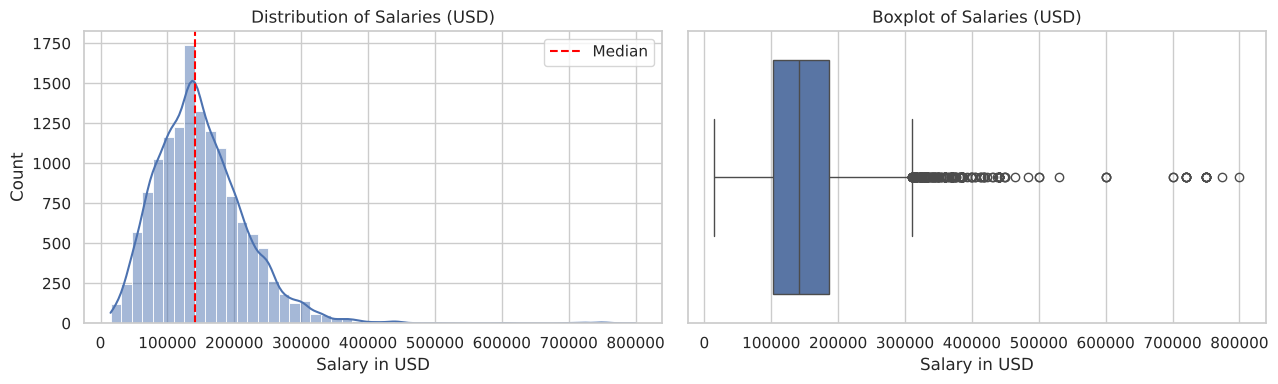

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["salary_in_usd"], bins=50, kde=True, ax=axes[0])
axes[0].axvline(df["salary_in_usd"].median(), color="red", linestyle="--", label="Median")
axes[0].set_title("Distribution of Salaries (USD)")
axes[0].set_xlabel("Salary in USD")
axes[0].legend()

sns.boxplot(x=df["salary_in_usd"], ax=axes[1])
axes[1].set_title("Boxplot of Salaries (USD)")
axes[1].set_xlabel("Salary in USD")

plt.tight_layout()
plt.show()

**Insight:** Most salaries are between **\$100K and \$190K** per year, with a long tail to the right. The boxplot shows many high outliers above about \$310K.

### 7.2 Salary by Experience Level

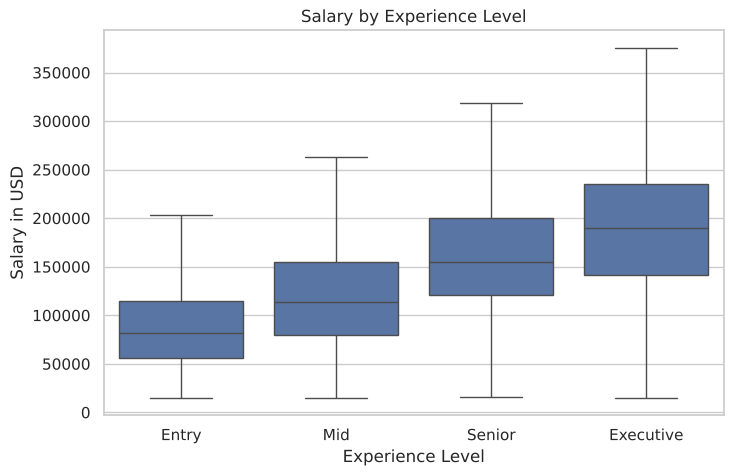

experience
Entry         82000.0
Mid          113250.0
Senior       155000.0
Executive    190000.0
Name: salary_in_usd, dtype: float64

In [ ]:
exp_order = ["Entry", "Mid", "Senior", "Executive"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="experience", y="salary_in_usd", order=exp_order, showfliers=False)
plt.title("Salary by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Salary in USD")
plt.show()

df.groupby("experience")["salary_in_usd"].median().reindex(exp_order)

**Insight:** Experience is the **strongest driver** of salary. The median salary of an executive is more than **double** the median of an entry-level employee.

### 7.3 Salary by Job Family

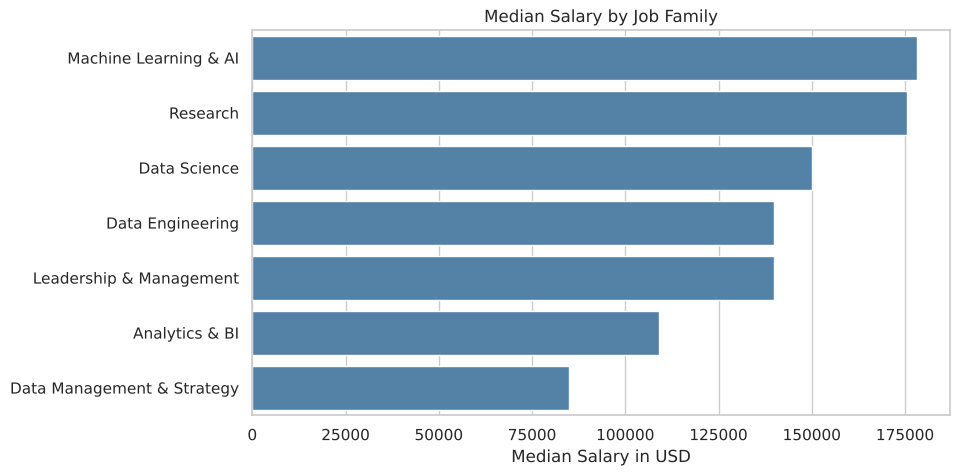

In [ ]:
family_median = df.groupby("job_family")["salary_in_usd"].median().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=family_median.values, y=family_median.index, color="steelblue")
plt.title("Median Salary by Job Family")
plt.xlabel("Median Salary in USD")
plt.ylabel("")
plt.show()

**Insight:** **Machine Learning & AI** and **Research** pay the most (about \$175K+), followed by **Data Science**. **Analytics & BI** and **Data Management** jobs have the lowest median salary.
Leadership is in the middle because this family mixes junior managers with directors and heads.

### 7.4 Top Paying Job Titles

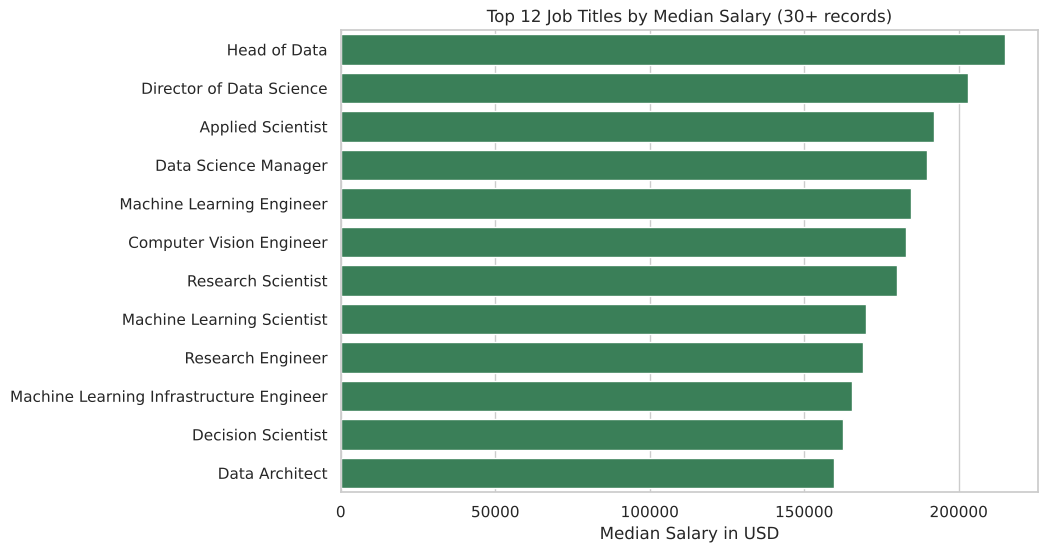

In [ ]:
# Only titles with at least 30 records, so the median is reliable
title_counts = df["job_title"].value_counts()
common_titles = title_counts[title_counts >= 30].index

title_median = (
    df[df["job_title"].isin(common_titles)]
    .groupby("job_title")["salary_in_usd"].median()
    .sort_values(ascending=False)
    .head(12)
)

plt.figure(figsize=(9, 6))
sns.barplot(x=title_median.values, y=title_median.index, color="seagreen")
plt.title("Top 12 Job Titles by Median Salary (30+ records)")
plt.xlabel("Median Salary in USD")
plt.ylabel("")
plt.show()

**Insight:** Research and machine learning titles lead the list, while classic analyst titles are at the bottom.

### 7.5 Salary by Country

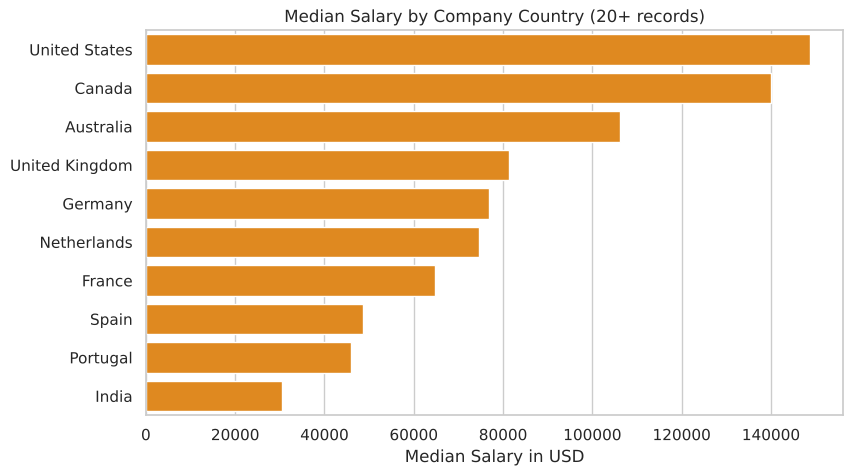

In [ ]:
# Countries with at least 20 records
country_counts = df["company_country"].value_counts()
common_countries = country_counts[country_counts >= 20].index

country_median = (
    df[df["company_country"].isin(common_countries)]
    .groupby("company_country")["salary_in_usd"].median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=country_median.values, y=country_median.index, color="darkorange")
plt.title("Median Salary by Company Country (20+ records)")
plt.xlabel("Median Salary in USD")
plt.ylabel("")
plt.show()

**Insight:** Location has a big effect. The **US** and **Canada** pay the most, while countries like **India** pay much less for similar jobs.

### 7.6 Work Setting and Company Size

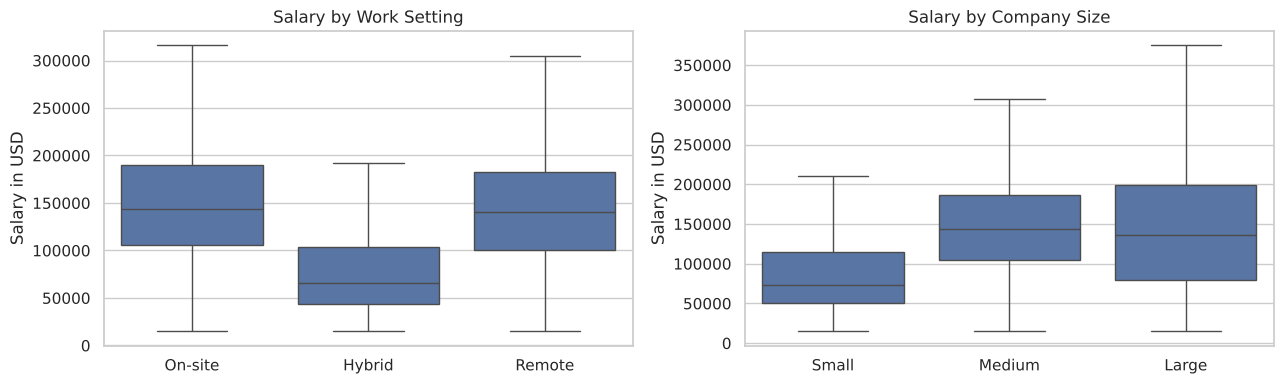

work_setting
On-site    0.658
Remote     0.325
Hybrid     0.017
Name: proportion, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df, x="work_setting", y="salary_in_usd", order=["On-site", "Hybrid", "Remote"],
            showfliers=False, ax=axes[0])
axes[0].set_title("Salary by Work Setting")
axes[0].set_xlabel("")
axes[0].set_ylabel("Salary in USD")

sns.boxplot(data=df, x="company_size", y="salary_in_usd", order=["Small", "Medium", "Large"],
            showfliers=False, ax=axes[1])
axes[1].set_title("Salary by Company Size")
axes[1].set_xlabel("")
axes[1].set_ylabel("Salary in USD")

plt.tight_layout()
plt.show()

print(df["work_setting"].value_counts(normalize=True).round(3))

**Insight:**
- **On-site** and **Remote** jobs have similar salaries, while **Hybrid** jobs are much lower (but they are less than 2% of the data, mostly outside the US).
- **Medium** companies pay the most. **Small** companies pay noticeably less.

### 7.7 Salary Trend Over the Years

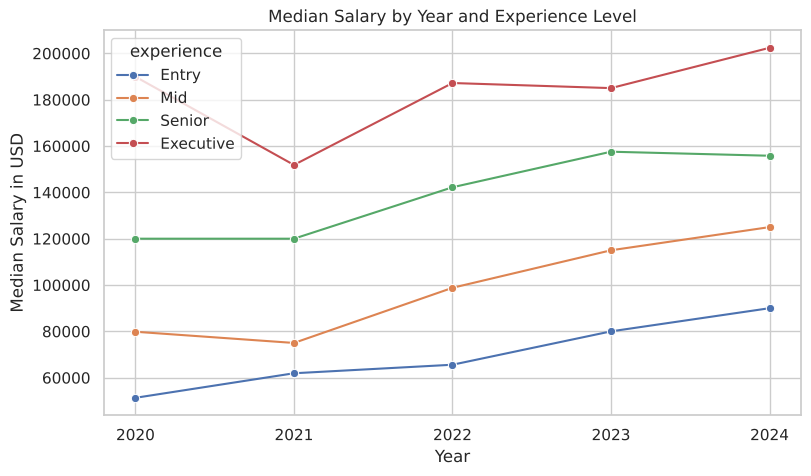

work_year
2020      75
2021     218
2022    1652
2023    8518
2024    3509
Name: count, dtype: int64

In [ ]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=df, x="work_year", y="salary_in_usd", hue="experience", hue_order=exp_order,
             estimator="median", errorbar=None, marker="o")
plt.title("Median Salary by Year and Experience Level")
plt.xlabel("Year")
plt.ylabel("Median Salary in USD")
plt.xticks(sorted(df["work_year"].unique()))
plt.show()

df["work_year"].value_counts().sort_index()

**Insight:** Salaries jumped between 2021 and 2023 and stayed almost flat in 2024. Note that 2020 and 2021 have very few records, so their values are less reliable.

### 7.8 Experience and Job Family Together

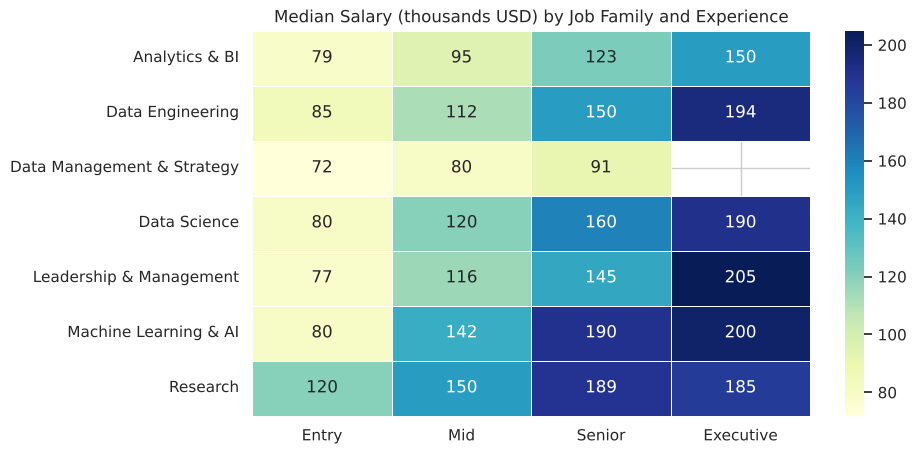

In [ ]:
pivot = df.pivot_table(index="job_family", columns="experience", values="salary_in_usd", aggfunc="median")
pivot = pivot[exp_order] / 1000

plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5)
plt.title("Median Salary (thousands USD) by Job Family and Experience")
plt.xlabel("")
plt.ylabel("")
plt.show()

**Insight:** The heatmap shows that experience matters in every family, but the gap between families also stays at every level. A senior ML engineer earns more than a senior analyst.

## 8. Saudi Arabia vs the World

Because the main dataset has only 2 Saudi rows, we use the benchmark sources.
We show the values in **SAR per month** (how salaries are usually discussed in Saudi Arabia) and in **USD per year** (how the main dataset is measured).

### 8.1 Saudi Salary Ranges by Source

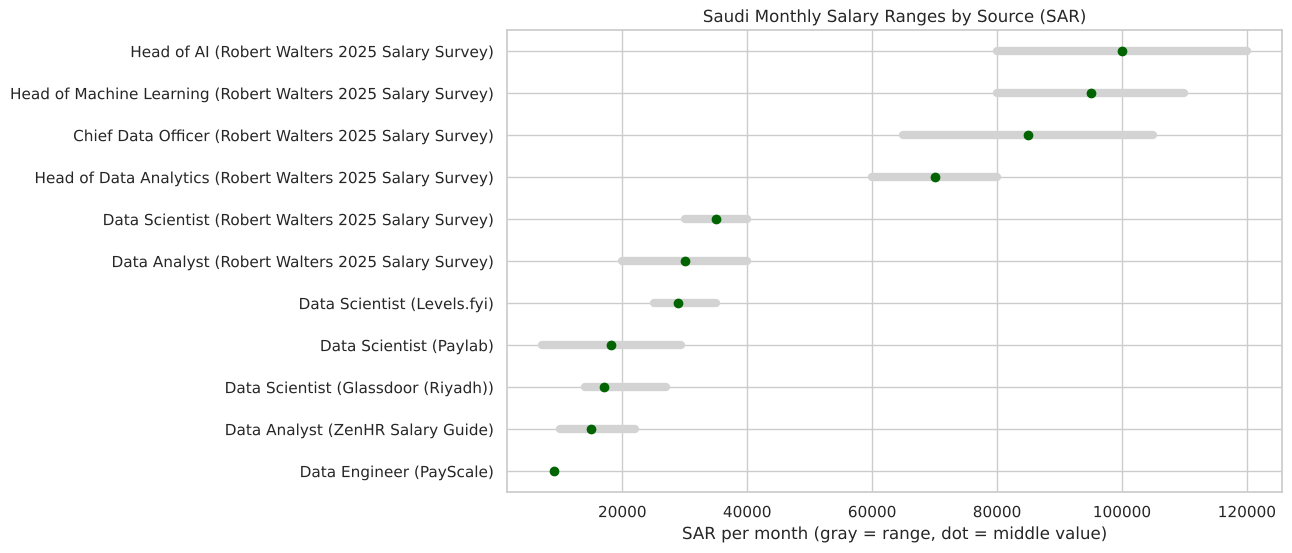

In [ ]:
plot_data = ksa_clean.copy()
plot_data["label"] = plot_data["role"] + " (" + plot_data["source"] + ")"
plot_data = plot_data.sort_values("mid_sar_month")

plt.figure(figsize=(10, 6))
for i, row in enumerate(plot_data.itertuples()):
    if pd.notna(row.min_sar_month) and pd.notna(row.max_sar_month):
        plt.plot([row.min_sar_month, row.max_sar_month], [i, i], color="lightgray", linewidth=6)
    plt.scatter(row.mid_sar_month, i, color="darkgreen", zorder=3)

plt.yticks(range(len(plot_data)), plot_data["label"])
plt.title("Saudi Monthly Salary Ranges by Source (SAR)")
plt.xlabel("SAR per month (gray = range, dot = middle value)")
plt.show()

**Insight:** The sources do not agree. For a Data Scientist, the middle value goes from about **17K SAR** (Glassdoor) to **35K SAR** (Robert Walters).
The reason is the method: recruiter surveys (Robert Walters) focus on advertised senior roles, while crowd-sourced sites include all levels.

### 8.2 Compare Each Saudi Role with the Same Role Globally

We match each benchmark role with the same group in the main dataset:
- Individual roles (Data Analyst, Data Scientist, Data Engineer) are matched with the same job title.
- Leadership roles (Head of ..., Chief Data Officer) are matched with the **Leadership & Management** family at **Senior and Executive** level.

In [ ]:
def global_group(role):
    if role in ["Data Analyst", "Data Scientist", "Data Engineer"]:
        return df[df["job_title"] == role]
    return df[(df["job_family"] == "Leadership & Management") & (df["experience"].isin(["Senior", "Executive"]))]

# one saudi value per role: the median of the middle values from all sources
saudi_role = ksa_clean.groupby("role")["mid_sar_month"].median()

rows = []
for role, saudi_sar in saudi_role.items():
    group = global_group(role)
    rows.append({
        "role": role,
        "saudi_sar_month": saudi_sar,
        "global_sar_month": group["salary_sar_month"].median(),
        "us_sar_month": group[group["company_location"] == "US"]["salary_sar_month"].median(),
        "non_us_sar_month": group[group["company_location"] != "US"]["salary_sar_month"].median(),
    })

compare = pd.DataFrame(rows).set_index("role")
compare["saudi_vs_global_%"] = (compare["saudi_sar_month"] / compare["global_sar_month"] * 100).round(0)
compare.round(0)

,saudi_sar_month,global_sar_month,us_sar_month,non_us_sar_month,saudi_vs_global_%
role,,,,,
Chief Data Officer,85000.0,48229.0,53125.0,39359.0,176.0
Data Analyst,22500.0,32500.0,33375.0,20130.0,69.0
Data Engineer,9000.0,43750.0,45369.0,24992.0,21.0
Data Scientist,23618.0,46875.0,48875.0,24305.0,50.0
Head of AI,100000.0,48229.0,53125.0,39359.0,207.0
Head of Data Analytics,70000.0,48229.0,53125.0,39359.0,145.0
Head of Machine Learning,95000.0,48229.0,53125.0,39359.0,197.0


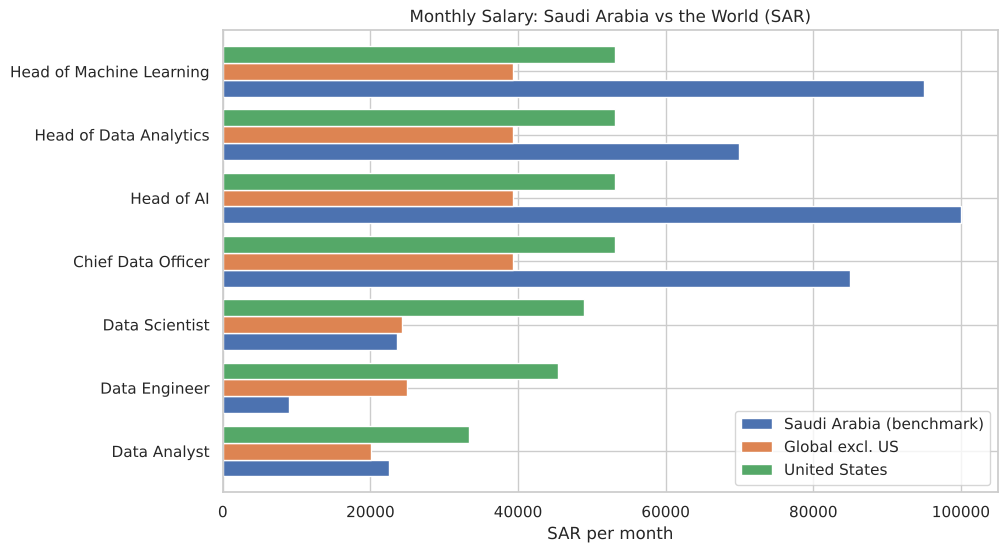

In [ ]:
compare_plot = compare[["saudi_sar_month", "non_us_sar_month", "us_sar_month"]].rename(columns={
    "saudi_sar_month": "Saudi Arabia (benchmark)",
    "non_us_sar_month": "Global excl. US",
    "us_sar_month": "United States",
})

compare_plot.sort_values("United States").plot(kind="barh", figsize=(10, 6), width=0.8)
plt.title("Monthly Salary: Saudi Arabia vs the World (SAR)")
plt.xlabel("SAR per month")
plt.ylabel("")
plt.legend(loc="lower right")
plt.show()

**Insight:**
- For **individual roles** (analyst, scientist, engineer), Saudi salaries are clearly **below the US** and closer to the global level **outside the US**.
- For **leadership roles**, the Saudi benchmark is **higher** than the global and even the US median. But these numbers come from one recruiter survey (Robert Walters) that covers top-level roles in large companies, while the global group also includes junior managers. So we read this as "Saudi Arabia pays well for senior data leaders", not as an exact gap.
- The **Data Engineer** value comes from one source only (PayScale, 9,000 SAR), so it is the least reliable number in this comparison.
- Saudi salaries usually come **tax-free** and often with **housing and transport allowances** that are not included in the "basic salary" sources, so the real gap is smaller than it looks.

### 8.3 Data Scientist: Saudi Arabia vs Top Countries

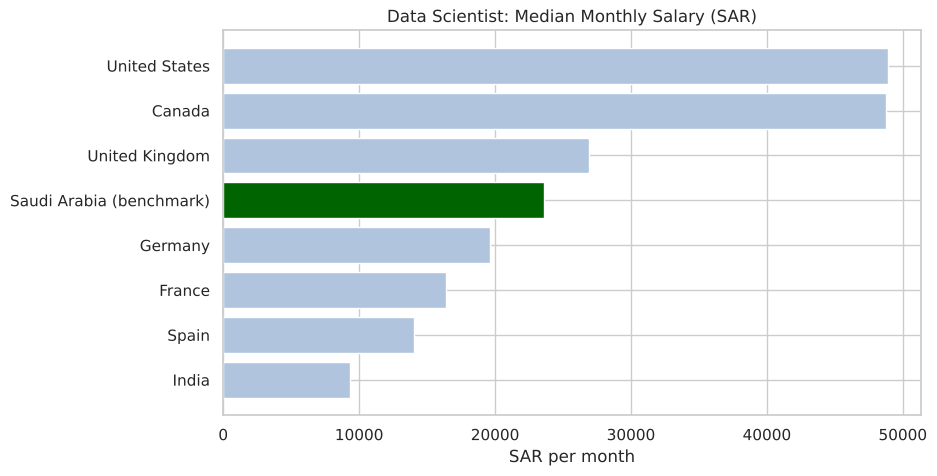

company_country
India                        29751.0
Spain                        44998.0
France                       52533.0
Germany                      62726.0
Saudi Arabia (benchmark)     75577.0
United Kingdom               86128.0
Canada                      156000.0
United States               156400.0
Name: USD per year, dtype: float64

In [ ]:
ds = df[df["job_title"] == "Data Scientist"]
ds_counts = ds["company_country"].value_counts()
ds_countries = ds_counts[ds_counts >= 10].index

ds_country = ds[ds["company_country"].isin(ds_countries)].groupby("company_country")["salary_sar_month"].median()

# add the saudi value (median of all saudi data scientist sources)
ds_country["Saudi Arabia (benchmark)"] = saudi_role["Data Scientist"]
ds_country = ds_country.sort_values()

colors = ["darkgreen" if "Saudi" in c else "lightsteelblue" for c in ds_country.index]

plt.figure(figsize=(9, 5))
plt.barh(ds_country.index, ds_country.values, color=colors)
plt.title("Data Scientist: Median Monthly Salary (SAR)")
plt.xlabel("SAR per month")
plt.show()

(ds_country / USD_TO_SAR * 12).round(0).rename("USD per year")

**Insight:** A Data Scientist in Saudi Arabia (about 23.6K SAR per month, or about \$76K per year) earns more than in India, Spain, France and Germany, a bit less than in the UK, and about half of the US and Canada.

## 9. Final Insights Summary

### 1. Experience is the biggest factor
Executives earn more than double the salary of entry-level employees.

### 2. The job family matters
Machine Learning & AI and Research pay the most. Analytics & BI and Data Management pay the least.

### 3. Location matters a lot
US and Canadian companies pay the highest salaries. The same job can pay several times less in other countries.

### 4. Remote work does not reduce salary
On-site and remote jobs have very similar salaries.

### 5. Saudi Arabia
- For individual roles, Saudi salaries are below the US but similar to or higher than many European countries.
- For leadership roles, the Saudi benchmark is higher than global levels.
- The benchmark sources disagree, so Saudi numbers should be read as a **range**, not as one exact value.

## 10. Data Preparation for ML

Before building the model, we prepare the data:
1. Remove duplicates (as decided in Section 5.1)
2. Remove salary outliers (IQR method)
3. Group rare job titles and countries into "Other"
4. Select the features (X) and the target (y)
5. Split the data into train and test sets

In [ ]:

model_df = df.drop_duplicates(subset=cols_without_id).copy()
print("Rows after removing duplicates:", len(model_df))

Q1 = model_df["salary_in_usd"].quantile(0.25)
Q3 = model_df["salary_in_usd"].quantile(0.75)
IQR = Q3 - Q1
model_df = model_df[(model_df["salary_in_usd"] >= Q1 - 1.5 * IQR) & (model_df["salary_in_usd"] <= Q3 + 1.5 * IQR)]
print("Rows after removing outliers  :", len(model_df))

Rows after removing duplicates: 8486
Rows after removing outliers  : 8333


In [ ]:
group rare categories: titles with less than 25 rows and countries with less than 20 rows
title_counts = model_df["job_title"].value_counts()
keep_titles = title_counts[title_counts >= 25].index.tolist()
model_df["title_group"] = np.where(model_df["job_title"].isin(keep_titles), model_df["job_title"], "Other")

country_counts = model_df["company_country"].value_counts()
keep_countries = country_counts[country_counts >= 20].index.tolist()
model_df["country_group"] = np.where(model_df["company_country"].isin(keep_countries), model_df["company_country"], "Other")

print("Titles kept   :", len(keep_titles))
print("Countries kept:", keep_countries)

Titles kept   : 27
Countries kept: ['United States', 'United Kingdom', 'Canada', 'Germany', 'Spain', 'India', 'France', 'Australia', 'Netherlands', 'Portugal']


### Why these features?

| Feature | Why we use it |
|---|---|
| `experience` | Strongest driver of salary (Section 7.2) |
| `job_family` | Big differences between families (Section 7.3) |
| `title_group` | Adds detail inside each family (Section 7.4) |
| `country_group` | Location has a big effect (Section 7.5) |
| `work_setting` | Small effect, but hybrid is different |
| `company_size` | Small companies pay less (Section 7.6) |
| `work_year` | Salaries changed over time (Section 7.7) |

We do **not** use:
- `salary`, `salary_currency` because of data leakage
- `employment_type` because 99.6% of the rows are Full-time
- `employee_residence` because it is almost always the same as `company_location`
- `ID` because it has no meaning

In [ ]:
# features
features = ["experience", "job_family", "title_group", "country_group", "work_setting", "company_size", "work_year"]

X = model_df[features].astype(str)
y = model_df["salary_in_usd"]

X.head()

,experience,job_family,title_group,country_group,work_setting,company_size,work_year
0,Senior,Machine Learning & AI,AI Engineer,Other,On-site,Large,2024
1,Senior,Machine Learning & AI,Machine Learning Engineer,United States,On-site,Medium,2024
2,Senior,Machine Learning & AI,Machine Learning Engineer,United States,On-site,Medium,2024
3,Senior,Machine Learning & AI,Machine Learning Engineer,Australia,On-site,Medium,2024
4,Senior,Machine Learning & AI,Machine Learning Engineer,Australia,On-site,Medium,2024


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape

((6666, 7), (1667, 7))

### Encoding and scaling

All our features are **categorical**, so we use **One-Hot Encoding**. We put the encoder inside a **Pipeline**, so the same encoding is applied to the training data, the test data and any new input in the Streamlit app.

We do **not** need scaling here: after one-hot encoding every feature is 0 or 1, and scaling 0/1 columns does not change their meaning (and tree models do not need scaling at all).

## 11. Train and Compare Models

We try four regression models:
- **Linear Regression** (simple baseline)
- **Ridge Regression** (linear with regularization)
- **Random Forest**
- **Gradient Boosting**

We compare them with **5-fold cross-validation** on the training data using **MAE**, **RMSE** and **R²**.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

encoder = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), features)])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, random_state=42),
}

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipe = Pipeline([("encoder", encoder), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    results.append({
        "Model": name,
        "MAE": -scores["test_neg_mean_absolute_error"].mean(),
        "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
        "R2": scores["test_r2"].mean(),
    })
    print(f"{name} done")

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.round(3)

Linear Regression done


Ridge Regression done


Random Forest done


Gradient Boosting done


,Model,MAE,RMSE,R2
0,Gradient Boosting,38610.042,48841.859,0.379
1,Ridge Regression,38857.653,48960.101,0.375
2,Linear Regression,38860.850,48970.076,0.375
3,Random Forest,39228.569,49645.083,0.358


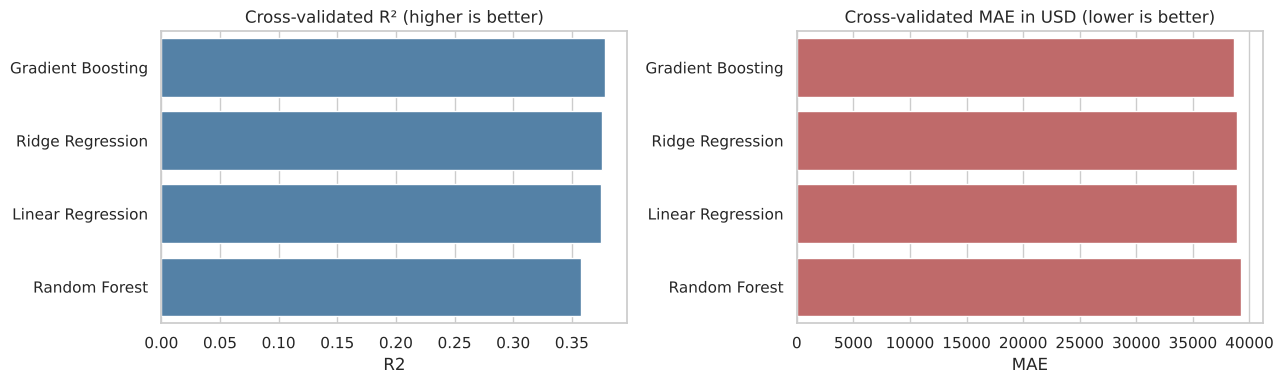

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=results_df, x="R2", y="Model", color="steelblue", ax=axes[0])
axes[0].set_title("Cross-validated R² (higher is better)")
axes[0].set_ylabel("")

sns.barplot(data=results_df, x="MAE", y="Model", color="indianred", ax=axes[1])
axes[1].set_title("Cross-validated MAE in USD (lower is better)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Result:** **Gradient Boosting** gives the best R² and the lowest error, so we choose it as our final model.

The differences between the models are small. This tells us that the limit is the **data**, not the model: the dataset does not include skills, company name, city or years of experience in numbers, which explain a big part of salary differences.

## 12. Evaluate the Best Model on the Test Set

In [ ]:
best_name = results_df.loc[0, "Model"]
best_model = Pipeline([("encoder", encoder), ("model", models[best_name])])
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print(f"Best model: {best_name}")
print(f"Test MAE  : ${test_mae:,.0f}")
print(f"Test RMSE : ${test_rmse:,.0f}")
print(f"Test R²   : {test_r2:.3f}")

Best model: Gradient Boosting
Test MAE  : $38,150
Test RMSE : $48,332
Test R²   : 0.399


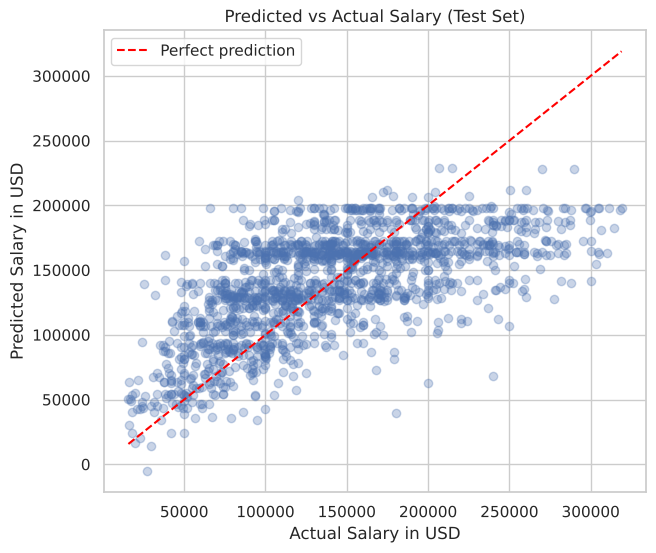

In [ ]:
# predicted vs actual salaries
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", label="Perfect prediction")
plt.title("Predicted vs Actual Salary (Test Set)")
plt.xlabel("Actual Salary in USD")
plt.ylabel("Predicted Salary in USD")
plt.legend()
plt.show()

**Insight:** The predictions follow the right direction, but they are pulled towards the middle: the model is good at the typical salaries and less accurate at the very high or very low ones.

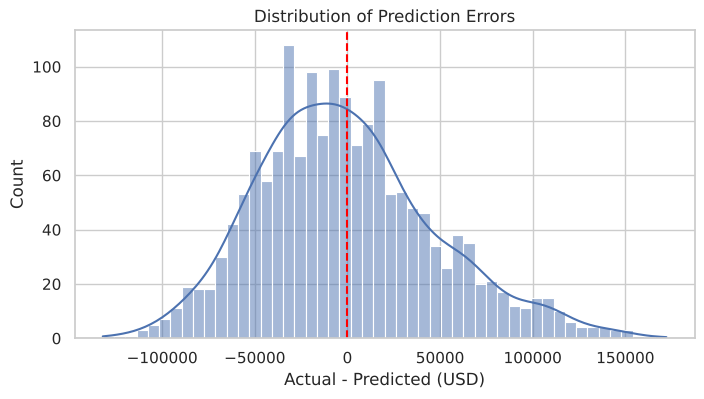

In [ ]:
# residuals: actual minus predicted
residuals = y_test - y_pred

plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=50, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual - Predicted (USD)")
plt.show()

### Which features matter most?

We use **permutation importance**: we shuffle one feature at a time and see how much the R² drops. A bigger drop means a more important feature.

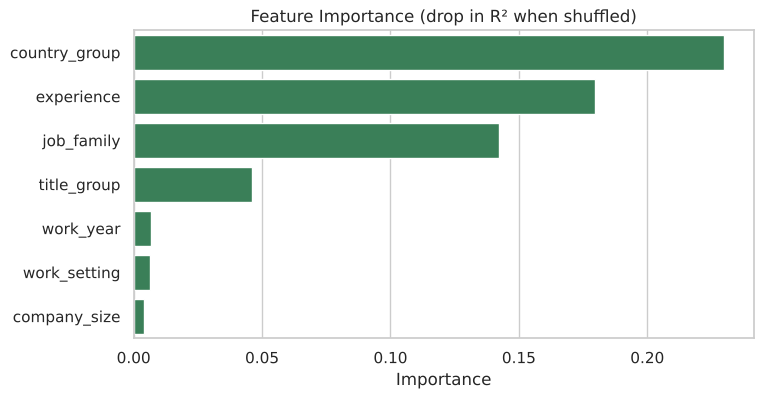

,feature,importance
3,country_group,0.229926
0,experience,0.179765
1,job_family,0.142133
2,title_group,0.045996
6,work_year,0.006808
4,work_setting,0.006331
5,company_size,0.004116


In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring="r2")

importance_df = pd.DataFrame({
    "feature": features,
    "importance": perm.importances_mean
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=importance_df, x="importance", y="feature", color="seagreen")
plt.title("Feature Importance (drop in R² when shuffled)")
plt.xlabel("Importance")
plt.ylabel("")
plt.show()

importance_df

**Insight:** **Country** and **experience** are the most important features, followed by the job title and job family. Work setting and company size add only a little. This matches what we saw in the EDA.

### Salary range instead of a single number

Because one number can be misleading, we also train two extra Gradient Boosting models with **quantile loss** to estimate a **likely range** (10th to 90th percentile) for each prediction.

In [ ]:
range_models = {}
for q in [0.1, 0.9]:
    q_model = Pipeline([
        ("encoder", encoder),
        ("model", GradientBoostingRegressor(loss="quantile", alpha=q, n_estimators=300, max_depth=3,
                                            learning_rate=0.05, random_state=42)),
    ])
    q_model.fit(X_train, y_train)
    range_models[q] = q_model

low = range_models[0.1].predict(X_test)
high = range_models[0.9].predict(X_test)
coverage = ((y_test >= low) & (y_test <= high)).mean()
print(f"Share of test salaries inside the predicted range: {coverage:.1%}")

Share of test salaries inside the predicted range: 78.3%


## 13. Save the Clean Data and the Model

We save everything the Streamlit app needs:
- The clean salaries dataset and the clean Saudi benchmark
- The final model and the two range models (retrained on **all** the model data)
- A small JSON file with the metrics, the options for the input form and the feature importance

In [ ]:
# retrain the final models on the models of all  data
final_model = Pipeline([("encoder", encoder), ("model", models[best_name])]).fit(X, y)
final_low = range_models[0.1].fit(X, y)
final_high = range_models[0.9].fit(X, y)

joblib.dump({"model": final_model, "low": final_low, "high": final_high, "features": features},
            "../models/salary_model.pkl")
print("Model saved!")

Model saved!


In [ ]:
# clean dataets
clean_cols = ["ID", "work_year", "experience", "employment", "job_title", "job_family", "salary_in_usd",
              "salary_sar_month", "company_country", "employee_country", "company_location",
              "work_setting", "remote_ratio", "company_size", "is_outlier"]
df[clean_cols].to_csv("../data/salaries_clean.csv", index=False)
ksa_clean.to_csv("../data/saudi_benchmark_clean.csv", index=False)

# test predictins for the app (actual vs predicted chart)
pd.DataFrame({"actual": y_test.values, "predicted": y_pred}).to_csv("../data/test_predictions.csv", index=False)

# metadata for the app
metadata = {
    "best_model": best_name,
    "cv_results": results_df.round(4).to_dict(orient="records"),
    "test_metrics": {"MAE": round(test_mae), "RMSE": round(test_rmse), "R2": round(test_r2, 4),
                     "range_coverage": round(float(coverage), 4)},
    "importance": importance_df.round(4).to_dict(orient="records"),
    "keep_titles": keep_titles,
    "keep_countries": keep_countries,
    "title_to_family": df.drop_duplicates("job_title").set_index("job_title")["job_family"].to_dict(),
    "rows_raw": int(len(df)),
    "rows_model": int(len(model_df)),
    "duplicates": int(dup_count),
    "titles_before": int(titles_before),
    "titles_after": int(titles_after),
    "usd_to_sar": USD_TO_SAR,
}
with open("../models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Clean data and metadata saved!")

Clean data and metadata saved!


## 14. Try the Model

In [ ]:
# xample: a senior machine learning engineer in a medium US company, working remotely in 2024
example = pd.DataFrame([{
    "experience": "Senior",
    "job_family": "Machine Learning & AI",
    "title_group": "Machine Learning Engineer",
    "country_group": "United States",
    "work_setting": "Remote",
    "company_size": "Medium",
    "work_year": "2024",
}])

pred = final_model.predict(example)[0]
print(f"Predicted salary: ${pred:,.0f} per year")
print(f"Likely range    : ${final_low.predict(example)[0]:,.0f} to ${final_high.predict(example)[0]:,.0f}")
print(f"In SAR          : {pred * USD_TO_SAR / 12:,.0f} SAR per month")

Predicted salary: $194,865 per year
Likely range    : $121,841 to $264,888
In SAR          : 60,895 SAR per month


## Conclusion

- We cleaned the data by unifying job titles, creating job families, making the labels readable and flagging outliers.
- The EDA showed that **experience**, **location** and **job family** are the main drivers of salary.
- Saudi Arabia pays less than the US for individual roles, but pays well for leadership roles.
- **Gradient Boosting** was the best model. It explains about 40% of the salary variation, which is reasonable for a dataset without skills or company details.
- The model and clean data are saved and used by the Streamlit app.